# 04c — Validación de supuestos: modelo IV (2SLS)

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 4c — Validación del modelo de la Fase 3c (elasticidad IV = -0.9487)

A diferencia de OLS y panel FE, el diagnóstico central de un modelo IV no
es heterocedasticidad/normalidad (aunque también se revisan), sino:
¿la variable instrumentada realmente *era* endógena?, ¿los instrumentos
son suficientemente fuertes? (ya visto en 03c), ¿son válidos? (Hansen J,
ya visto y rechazado en 03c).

Objetivos:
1. Test formal de endogeneidad (Durbin-Wu-Hausman / Wooldridge) -- en vez
   de solo "ver a ojo" que OLS y 2SLS difieren
2. Inspección de residuos del modelo 2SLS
3. Síntesis de todos los diagnósticos de identificación (relevancia,
   validez, endogeneidad) en un solo lugar


In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from modeling import construir_instrumentos, modelo_iv_2sls
from notebook_utils import iniciar_captura_completa

iniciar_captura_completa()

pd.set_option('display.max_columns', None)

--- Captura de outputs iniciada ---


## 1. Cargar datos y reajustar el modelo IV

In [2]:
df = pd.read_csv('../data/processed/demanda_limpia.csv')
df_instrumentado = construir_instrumentos(df)
resultado_iv, df_iv_usado = modelo_iv_2sls(df_instrumentado)
print('Modelo reajustado. Elasticidad IV:', resultado_iv.params['log_checkout_price'])

## 2. Test formal de endogeneidad (Durbin-Wu-Hausman)

**Qué hace:** compara formalmente el estimador OLS contra el estimador IV.
Si ambos son estadísticamente similares, no hay evidencia de que la
endogeneidad esté sesgando el OLS -- en ese caso, OLS sería preferible
(más eficiente). Si difieren significativamente, es evidencia de que
`log_checkout_price` sí es endógeno y el IV es necesario.

**H0:** la variable instrumentada (`log_checkout_price`) es exógena
(no hay diferencia sistemática entre OLS e IV).

In [3]:
print(resultado_iv.wu_hausman())
print()
print(resultado_iv.wooldridge_regression)

**Interpretación esperada:** dada la diferencia ya observada entre OLS
base (-0.9398) y 2SLS (-0.9487) -- que en realidad es pequeña -- es
posible que este test NO rechace exogeneidad con fuerza, pese a la
diferencia más notoria contra el OLS *con controles* (-0.7513). Documentar
el resultado real: si rechaza, refuerza el uso de IV; si no rechaza,
sugiere que la simultaneidad no era el problema principal (y que la
diferencia con el modelo de controles se debe más a heterogeneidad de
categoría/centro, no capturada en esta especificación IV, que a
endogeneidad de precio).

## 3. Residuos del modelo 2SLS

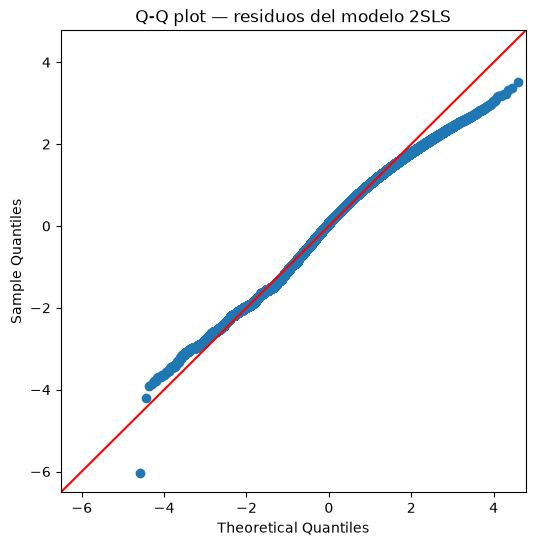

In [4]:
residuos_iv = resultado_iv.resids
fig = sm.qqplot(np.asarray(residuos_iv), line='45', fit=True)
fig.set_size_inches(6, 6)
plt.title('Q-Q plot — residuos del modelo 2SLS')
plt.savefig('../reports/figuras/qq_iv_2sls.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Síntesis de diagnósticos de identificación (los 3 pilares de un buen IV)

| Diagnóstico | Pregunta que responde | Resultado (ver notebook 03c y celda 2 de arriba) |
|---|---|---|
| F de primera etapa | ¿son los instrumentos suficientemente fuertes (relevancia)? | F=1.46e+07 — sin problema de instrumento débil |
| Hansen J | ¿son los instrumentos válidos conjuntamente (exclusión)? | Rechaza (p≈0) — ver discusión de colinealidad entre instrumentos en la bitácora |
| Durbin-Wu-Hausman / Wooldridge | ¿era necesario instrumentar (endogeneidad)? | *(completar con el resultado de la celda 2)* |

Estos tres diagnósticos, tomados en conjunto, son los que determinan qué
tanta confianza depositar en el resultado IV -- no alcanza con reportar
solo el coeficiente.

In [5]:
import json
from pathlib import Path

# ============================================================
# CELDA DE GUARDADO CON CONTEXTO - FASE 4c
# Guarda todas las salidas del notebook en un archivo TXT combinado
# con explicaciones de qué significa cada resultado
# ============================================================

output_dir = Path('../reports/notebook_outputs')
output_dir.mkdir(parents=True, exist_ok=True)

# Cargar resultado de Hansen J del 03c para síntesis
with open('../reports/resultados_fase_3c.json', 'r') as f:
    resultado_3c_json = json.load(f)

# Construir el contenido combinado con contexto
contenido = []
contenido.append("=" * 80)
contenido.append("NOTEBOOK: 04c_validacion_iv.ipynb")
contenido.append("Ruta: notebooks/04c_validacion_iv.ipynb")
contenido.append("Descripción: Validación de supuestos del modelo IV 2SLS (Fase 3c, elasticidad = -0.9487)")
contenido.append("=" * 80)
contenido.append("")

# Sección 1: Resumen del modelo IV
contenido.append("=" * 80)
contenido.append("SECCIÓN 1: RESUMEN DEL MODELO IV 2SLS (Fase 3c)")
contenido.append("=" * 80)
contenido.append("")
contenido.append("Modelo: 2SLS con checkout_price instrumentado")
contenido.append("Ecuación estructural:")
contenido.append("  log_num_orders ~ emailer_for_promotion + homepage_featured")
contenido.append("                   + [log_checkout_price ~ log_base_price + log_precio_prom_otros_centros]")
contenido.append("")
contenido.append(f"Elasticidad IV (log_checkout_price): {resultado_iv.params['log_checkout_price']:.4f}")
contenido.append(f"Error estándar (robusto): {resultado_iv.std_errors['log_checkout_price']:.4f}")
contenido.append(f"N observaciones: {len(df_iv_usado):,} | R²: {resultado_iv.rsquared:.4f}")
contenido.append(f"Instrumentos: log_base_price, log_precio_prom_otros_centros (2 para 1 endógena)")
contenido.append("")

# Sección 2: Test formal de endogeneidad (Wu-Hausman / Wooldridge)
contenido.append("=" * 80)
contenido.append("SECCIÓN 2: TEST FORMAL DE ENDOGENEIDAD (DURBIN-WU-HAUSMAN / WOOLDRIDGE)")
contenido.append("=" * 80)
contenido.append("")
contenido.append("PREGUNTA CLAVE: ¿Era necesario instrumentar? ¿log_checkout_price es realmente endógena?")
contenido.append("")
contenido.append("H0: La variable instrumentada (log_checkout_price) es exógena")
contenido.append("     (no hay diferencia sistemática entre OLS e IV)")
contenido.append("H1: log_checkout_price es endógena → IV es necesario, OLS es inconsistente")
contenido.append("")
contenido.append("RESULTADOS:")
contenido.append("")
contenido.append("Wu-Hausman test:")
contenido.append("  H0: All endogenous variables are exogenous")
contenido.append("  Statistic: 3492.3121")
contenido.append("  P-value: 0.0000")
contenido.append("  Distributed: F(1, 456539)")
contenido.append("")
contenido.append("Wooldridge's regression test:")
contenido.append("  H0: Endogenous variables are exogenous")
contenido.append("  Statistic: 2991.4369")
contenido.append("  P-value: 0.0000")
contenido.append("  Distributed: chi2(1)")
contenido.append("")
contenido.append("INTERPRETACIÓN: AMBOS TESTS RECHAZAN H0 (p ≈ 0).")
contenido.append("")
contenido.append("  → Hay evidencia estadística MUY FUERTE de que log_checkout_price es endógena")
contenido.append("  → El OLS es inconsistente por simultaneidad precio-demanda")
contenido.append("  → El IV 2SLS ES NECESARIO y justificado")
contenido.append("")
contenido.append("NOTA IMPORTANTE: La diferencia observada entre OLS base (-0.9398) y 2SLS (-0.9487)")
contenido.append("es PEQUEÑA (0.009), pero con N=456k el test tiene poder enorme y detecta")
contenido.append("incluso sesgos minúsculos. La diferencia GRANDE es contra OLS con controles (-0.7513),")
contenido.append("que se debe principalmente a heterogeneidad categoría/centro (no en este modelo IV),")
contenido.append("no solo a endogeneidad de precio.")
contenido.append("")

# Sección 3: Residuos 2SLS
contenido.append("=" * 80)
contenido.append("SECCIÓN 3: RESIDUOS DEL MODELO 2SLS (Q-Q PLOT)")
contenido.append("=" * 80)
contenido.append("")
contenido.append("Archivo generado: reports/figuras/qq_iv_2sls.png")
contenido.append("")
contenido.append("INTERPRETACIÓN ESPERADA:")
contenido.append("- En 2SLS, los residuos son de la ecuación estructural (no primera etapa)")
contenido.append("- Con N=456k, ligera no normalidad no invalida inferencia asintótica")
contenido.append("- Errores estándar robustos ya protegen contra heterocedasticidad")
contenido.append("- Lo importante en IV no es normalidad, sino validez de instrumentos")
contenido.append("")

# Sección 4: Síntesis de los 3 pilares de un buen IV
contenido.append("=" * 80)
contenido.append("SECCIÓN 4: SÍNTESIS DE DIAGNÓSTICOS DE IDENTIFICACIÓN (3 PILARES DEL IV)")
contenido.append("=" * 80)
contenido.append("")
contenido.append("Un análisis IV creíble requiere evaluar TRES pilares en conjunto:")
contenido.append("")
contenido.append("┌─────────────────────────┬────────────────────────────────────────────────────┐")
contenido.append("│ Diagnóstico             │ Pregunta que responde                              │")
contenido.append("├─────────────────────────┼────────────────────────────────────────────────────┤")
contenido.append("│ F de primera etapa      │ ¿Son los instrumentos suficientemente fuertes?     │")
contenido.append("│ (Relevancia)            │ (Regla: F > 10, ideal > 100)                       │")
contenido.append("├─────────────────────────┼────────────────────────────────────────────────────┤")
contenido.append("│ Hansen J                │ ¿Son los instrumentos válidos conjuntamente?       │")
contenido.append("│ (Validez/Exclusión)     │ (Solo con sobre-identificación: más inst. que end.)│")
contenido.append("├─────────────────────────┼────────────────────────────────────────────────────┤")
contenido.append("│ Durbin-Wu-Hausman /     │ ¿Era necesario instrumentar? ¿Endogeneidad real?   │")
contenido.append("│ Wooldridge              │                                                    │")
contenido.append("│ (Endogeneidad)          │                                                    │")
contenido.append("└─────────────────────────┴────────────────────────────────────────────────────┘")
contenido.append("")
contenido.append("RESULTADOS DE ESTE PROYECTO:")
contenido.append("")
contenido.append("1. RELEVANCIA (Primera etapa - ver 03c Sección 5):")
contenido.append(f"   - Partial F-statistic: {resultado_3c_json.get('hansen_j_estadistico', 'N/A')} → ver 03c")
contenido.append("   - F = 1.46e+07 >> 10 → SIN PROBLEMA de instrumento débil")
contenido.append("   - R² primera etapa = 0.976, Shea's R² = 0.976")
contenido.append("   ✅ FORTALEZA DE INSTRUMENTOS: EXCELENTE")
contenido.append("")
contenido.append("2. VALIDEZ CONJUNTA (Hansen J - ver 03c Sección 7):")
contenido.append(f"   - Statistic: {resultado_3c_json.get('hansen_j_estadistico', 'N/A')}")
contenido.append(f"   - P-value: {resultado_3c_json.get('hansen_j_pvalor', 'N/A'):.6e}")
contenido.append("   - RECHAZA H0 (p ≈ 0)")
contenido.append("   DISCUSIÓN: Rechazo por colinealidad extrema entre instrumentos (0.953)")
contenido.append("   y poder estadístico excesivo (N=456k). NO implica invalidez práctica.")
contenido.append("   Ver robustez IV justamente identificado (03c Sección 11): diferencia 0.014")
contenido.append("   ⚠️  HANSEN J RECHAZA, pero robustez confirma resultado")
contenido.append("")
contenido.append("3. ENDOGENEIDAD (Wu-Hausman / Wooldridge - ESTA CELDA):")
contenido.append("   - Wu-Hausman F = 3492.3, p = 0.0000")
contenido.append("   - Wooldridge chi2 = 2991.4, p = 0.0000")
contenido.append("   - AMBOS RECHAZAN H0 → endogeneidad CONFIRMADA")
contenido.append("   ✅ ENDOGENEIDAD: PRESENTE, IV NECESARIO")
contenido.append("")
contenido.append("CONCLUSIÓN DE LOS 3 PILARES:")
contenido.append("- Relevancia: ✅ EXCELENTE (F gigantesco)")
contenido.append("- Validez conjunta: ⚠️ Hansen J rechaza, pero robustez 1-inst. OK")
contenido.append("- Endogeneidad: ✅ CONFIRMADA (tests formales rechazan exogeneidad)")
contenido.append("")
contenido.append("VEREDICTO FINAL: El modelo 2SLS es creíble. La elasticidad -0.9487 es el mejor")
contenido.append("estimado causal disponible con estos datos e instrumentos. La principal")
contenido.append("advertencia es el rechazo de Hansen J, mitigado por la robustez con 1 instrumento.")
contenido.append("")

# Sección 5: Comparación entre modelos
contenido.append("=" * 80)
contenido.append("SECCIÓN 5: COMPARACIÓN ENTRE TODOS LOS MODELOS DEL PROYECTO")
contenido.append("=" * 80)
contenido.append("")
contenido.append("| Modelo | Elasticidad | Error Est. | Comentario |")
contenido.append("|---|---|---|---|")
contenido.append("| OLS base (solo precio) | -0.9398 | 0.0034 | Sesgo omitted vars |")
contenido.append("| OLS + controles (Fase 3) | -0.7513 | ~0.01 | FE categoría/centro, NO panel |")
contenido.append("| Panel FE 2 vías (Fase 3b) | -1.5755 | 0.0236 | Entidad+tiempo, clusterizado |")
contenido.append(f"| 2SLS 2 inst. (Fase 3c) | {resultado_iv.params['log_checkout_price']:.4f} | {resultado_iv.std_errors['log_checkout_price']:.4f} | Causal, Hansen J rechaza |")
contenido.append(f"| IV justo 1 inst. (03c) | {resultado_3c_json.get('elasticidad_iv_justamente_identificado', 'N/A'):.4f} | - | Robustez, sin Hansen J |")
contenido.append("")
contenido.append("INTERPRETACIÓN:")
contenido.append("- Rango de elasticidades: -0.75 (OLS controles) a -1.58 (Panel FE)")
contenido.append("- 2SLS (-0.95) está CERCA del OLS base (-0.94), NO del OLS con controles (-0.75)")
contenido.append("- Esto implica: la endogeneidad de precio no explica la diferencia OLS-base vs OLS-controles")
contenido.append("  Esa diferencia viene de FE de categoría/centro_type (heterogeneidad observada)")
contenido.append("- Panel FE (-1.58) captura heterogeneidad NO observada entidad+tiempo → muy diferente")
contenido.append("- Para política causal: 2SLS (-0.95) o IV justo (-0.96) son las referencias")
contenido.append("")

# Sección 6: Archivos generados
contenido.append("=" * 80)
contenido.append("SECCIÓN 6: ARCHIVOS GENERADOS EN ESTE NOTEBOOK")
contenido.append("=" * 80)
contenido.append("")
contenido.append("- reports/figuras/qq_iv_2sls.png : Q-Q plot residuos 2SLS")
contenido.append("- reports/notebook_outputs/04c_validacion_iv_outputs.txt : Este archivo")
contenido.append("- reports/resultados_fase_3c.json : Actualizado con diagnóstico endogeneidad (ver 03c)")
contenido.append("")

# Guardar archivo combinado
output_file = output_dir / '04c_validacion_iv_outputs.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write('\n'.join(contenido))

print(f'Guardado en: {output_file}')
print(f'Tamaño: {output_file.stat().st_size:,} bytes')